# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Patrick Lee, Nathan Brence, Tesher Baer, Jason Zermani

**Date:** 11/16/2026

In [13]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

df = pd.read_csv(
    "heart_failure_clinical_records_dataset.csv"
)

print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.describe())

df = df.dropna().copy()
X = df.drop(columns="DEATH_EVENT")
y = df["DEATH_EVENT"]


(299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
              age     anaemia  creatinine_phosphokinase    diabetes  \
count  299.000000  299.000000     

In [14]:
from sklearn.metrics import r2_score

tree_preds = {}
linear_preds = {}

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)

tree = DecisionTreeRegressor(
    max_depth=3, random_state=100
).fit(X_train, y_train)

linear = LinearRegression().fit(X_train, y_train)

tree_pred = tree.predict(X_test)
linear_pred = linear.predict(X_test)

tree_preds.update({"Seed 100": tree_pred})
linear_preds.update({"Seed 100": linear_pred})

print("Tree test R^2:", r2_score(y_test, tree_pred))
print("Linear test R^2:", r2_score(y_test, linear_pred))

Tree test R^2: 0.3364247334920536
Linear test R^2: 0.24896175016286703


In [15]:
tree_coefs = {}
linear_coefs = {}

for i in range(1, 4):
    X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=i
    )

    tree = DecisionTreeRegressor(
        max_depth=3, random_state=i
    ).fit(X_train, y_train)

    linear = LinearRegression().fit(X_train, y_train)

    tree_pred = tree.predict(X_test)
    linear_pred = linear.predict(X_test)

    tree_coefs.update({f"Seed {i}": tree.feature_importances_})
    linear_coefs.update({f"Seed {i}": linear.coef_})
    tree_preds.update({f"Seed {i}": tree_pred})
    linear_preds.update({f"Seed {i}": linear_pred})

    print("Seed", i, "\nTree test R^2:", r2_score(y_test, tree_pred))
    print("Linear test R^2:", r2_score(y_test, linear_pred))

display(pd.DataFrame(tree_coefs, index=X.columns))
display(pd.DataFrame(linear_coefs, index=X.columns))

Seed 1 
Tree test R^2: 0.41262169468230137
Linear test R^2: 0.2899729047614722
Seed 2 
Tree test R^2: 0.5203987574111705
Linear test R^2: 0.4566414106242893
Seed 3 
Tree test R^2: 0.4638107037379031
Linear test R^2: 0.3202618248225543


,Seed 1,Seed 2,Seed 3
age,0.000000,0.048000,0.050948
anaemia,0.000000,0.000000,0.000000
creatinine_phosphokinase,0.000000,0.030112,0.026629
diabetes,0.000000,0.000000,0.000000
ejection_fraction,0.098409,0.076652,0.038034
high_blood_pressure,0.000000,0.000000,0.000000
platelets,0.000000,0.000000,0.000000
serum_creatinine,0.142939,0.155862,0.126958
serum_sodium,0.066890,0.048688,0.047171
sex,0.000000,0.000000,0.000000


,Seed 1,Seed 2,Seed 3
age,5.044082e-03,5.582838e-03,7.308635e-03
anaemia,-1.191866e-02,6.265691e-03,-4.743116e-02
creatinine_phosphokinase,3.241674e-05,5.070252e-05,5.695708e-05
diabetes,5.523460e-02,6.987862e-03,1.937374e-03
ejection_fraction,-9.993306e-03,-9.253683e-03,-1.056033e-02
high_blood_pressure,-4.191933e-02,-3.136866e-02,-4.414693e-02
platelets,-4.256004e-07,-6.095841e-08,-2.816988e-08
serum_creatinine,9.066341e-02,9.336067e-02,7.239187e-02
serum_sodium,-7.898632e-03,-5.859968e-03,-7.931276e-03
sex,-5.205687e-02,-7.467813e-02,-4.455962e-02


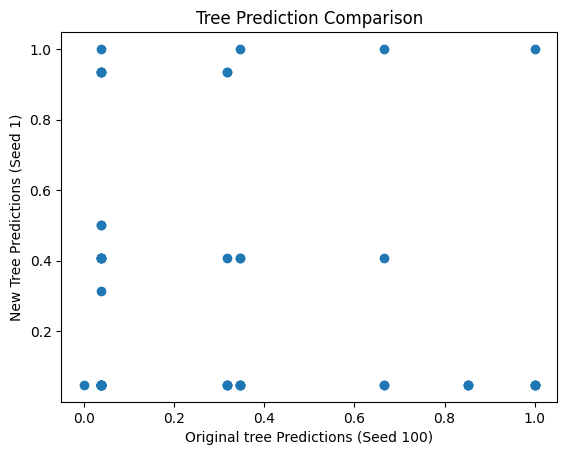

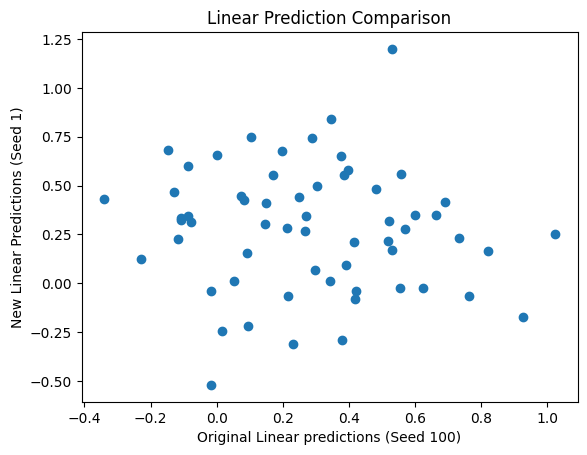

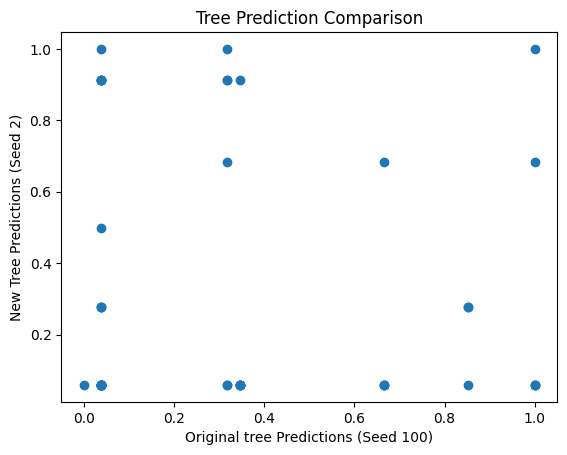

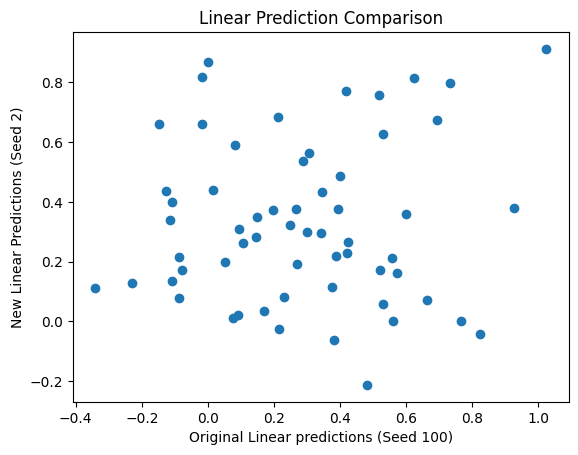

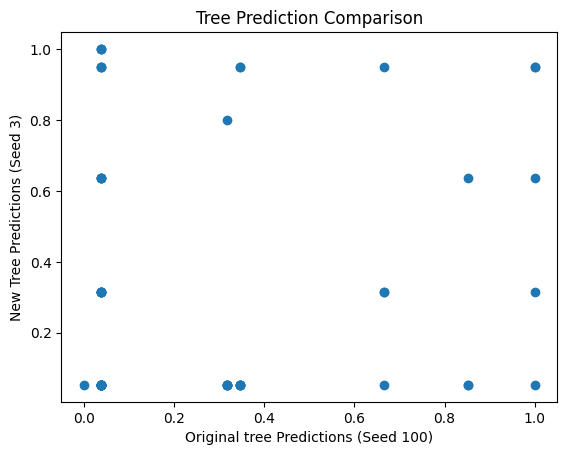

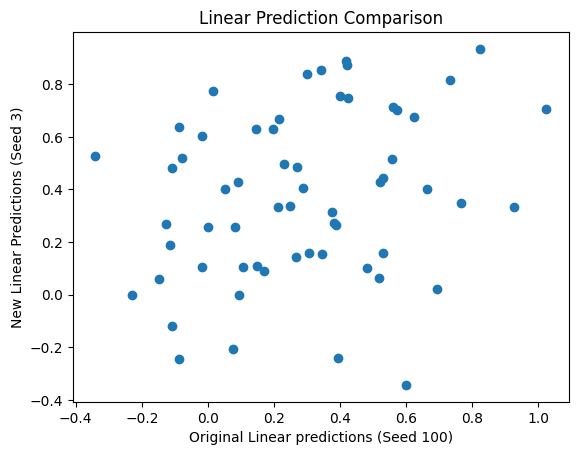

Decision Tree Correlations:
Seed 100 vs Seed 1: -0.0313
Seed 100 vs Seed 2: 0.0715
Seed 100 vs Seed 3: 0.1308

Linear Model Correlations:
Seed 100 vs Seed 1: -0.0822
Seed 100 vs Seed 2: 0.0734
Seed 100 vs Seed 3: 0.2541

Decision Tree Regressions:

Seed 100 vs Seed 1
Intercept: 0.2824
Slope: -0.0329
R²: 0.0010

Seed 100 vs Seed 2
Intercept: 0.2566
Slope: 0.0769
R²: 0.0051

Seed 100 vs Seed 3
Intercept: 0.2916
Slope: 0.1453
R²: 0.0171

Linear Model Regressions:

Seed 100 vs Seed 1
Intercept: 0.3041
Slope: -0.0870
R²: 0.0068

Seed 100 vs Seed 2
Intercept: 0.3110
Slope: 0.0659
R²: 0.0054

Seed 100 vs Seed 3
Intercept: 0.2955
Slope: 0.2671
R²: 0.0646


In [16]:
#question 4

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

#par a
import matplotlib.pyplot as plt

seeds = [1,2,3]

for seed in seeds:

    plt.scatter(tree_preds["Seed 100"], tree_preds[f"Seed {seed}"])
    plt.xlabel("Original tree Predictions (Seed 100)")
    plt.ylabel("New Tree Predictions (Seed " + str(seed) + ")")
    plt.title("Tree Prediction Comparison")
    plt.show()
    plt.scatter(linear_preds["Seed 100"], linear_preds[f"Seed {seed}"])
    plt.xlabel("Original Linear predictions (Seed 100)")
    plt.ylabel("New Linear Predictions (Seed " + str(seed) + ")")
    plt.title("Linear Prediction Comparison")
    plt.show()


#par b
tree_preds = pd.DataFrame(tree_preds)
linear_preds = pd.DataFrame(linear_preds)

print("Decision Tree Correlations:")

for seed in seeds:
    corr = tree_preds["Seed 100"].corr(tree_preds[f"Seed {seed}"])
    print(f"Seed 100 vs Seed {seed}: {corr:.4f}")

print("\nLinear Model Correlations:")

for seed in seeds:
    corr = linear_preds["Seed 100"].corr(linear_preds[f"Seed {seed}"])
    print(f"Seed 100 vs Seed {seed}: {corr:.4f}")


#part c
print("\nDecision Tree Regressions:")

for seed in seeds:
    X_reg = tree_preds[["Seed 100"]]
    y_reg = tree_preds[f"Seed {seed}"]

    reg = LinearRegression().fit(X_reg, y_reg)

    print(f"\nSeed 100 vs Seed {seed}")
    print(f"Intercept: {reg.intercept_:.4f}")
    print(f"Slope: {reg.coef_[0]:.4f}")
    print(f"R²: {reg.score(X_reg, y_reg):.4f}")

print("\nLinear Model Regressions:")

for seed in seeds:
    X_reg = linear_preds[["Seed 100"]]
    y_reg = linear_preds[f"Seed {seed}"]

    reg = LinearRegression().fit(X_reg, y_reg)

    print(f"\nSeed 100 vs Seed {seed}")
    print(f"Intercept: {reg.intercept_:.4f}")
    print(f"Slope: {reg.coef_[0]:.4f}")
    print(f"R²: {reg.score(X_reg, y_reg):.4f}")

Question 5: The linear models have relatively similar coefficients and predictions across the different training and test splits. Their correlations stay fairly consistent and are .957, .9698, and .9892 for seeds 1, 2, and 3 respectively. However, the decision trees have larger variation across the three different splits. Their correlations are .8167, .7398, and .8492 for seeds 1, 2, and 3 respectively. Overall, the linear models are more consistent across training and test splits, whereas the decision trees are less consistent and more sensitive to changes in the training data.

Question 6: The statement is generally true for the dataset, especially for the linear models. Their predictions have correlations of about 0.96–0.99 across splits with regression slopes close to 1 and intercepts close to 0 and R^2 values of about 0.92–0.98. This shows that changes in coefficients do not necessarily produce large changes in predictions. The trees also produce similar predictions but less consistently. Their correlations are about 0.74–0.85 and comparison R&2 values are about 0.55–0.72. I think overall the models can change in appearance while keeping similar predictions although the trees shows lower predictability.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 87682caf402d6bce2a773fbb4abfbdcc70981092
- **AI tool and model used:** Claude

### *Prompts used

1. For the following questions and answers, give a series of suggestions to improve the answers based on the questions that are given. Make sure each suggestion is relevant to the wording and requirements of each question. Give a numbered list of the suggestions as a summary at the bottom of your response

Questions:
1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
   
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
   
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
   
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the R2 close to 1?


5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."
Answers:
#Question 1:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression


df = pd.read_csv(
    "heart_failure_clinical_records_dataset.csv"
)


print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.describe())


df = df.dropna().copy()
X = df.drop(columns="DEATH_EVENT")
y = df["DEATH_EVENT"]


#Question 2
from sklearn.metrics import r2_score


tree_preds = {}
linear_preds = {}


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)


tree = DecisionTreeRegressor(
    max_depth=3, random_state=100
).fit(X_train, y_train)


linear = LinearRegression().fit(X_train, y_train)


tree_pred = tree.predict(X_test)
linear_pred = linear.predict(X_test)


tree_preds.update({"Seed 100": tree_pred})
linear_preds.update({"Seed 100": linear_pred})


print("Tree test R^2:", r2_score(y_test, tree_pred))
print("Linear test R^2:", r2_score(y_test, linear_pred))
#Question 3:
tree_coefs = {}
linear_coefs = {}


for i in range(1, 4):
    X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=i
    )


    tree = DecisionTreeRegressor(
        max_depth=3, random_state=i
    ).fit(X_train, y_train)


    linear = LinearRegression().fit(X_train, y_train)


    tree_pred = tree.predict(X_test)
    linear_pred = linear.predict(X_test)


    tree_coefs.update({f"Seed {i}": tree.feature_importances_})
    linear_coefs.update({f"Seed {i}": linear.coef_})
    tree_preds.update({f"Seed {i}": tree_pred})
    linear_preds.update({f"Seed {i}": linear_pred})


    print("Seed", i, "\nTree test R^2:", r2_score(y_test, tree_pred))
    print("Linear test R^2:", r2_score(y_test, linear_pred))


display(pd.DataFrame(tree_coefs, index=X.columns))
display(pd.DataFrame(linear_coefs, index=X.columns))


#Question 4:


import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression


#par a
import matplotlib.pyplot as plt


seeds = [1,2,3]


for seed in seeds:


    plt.scatter(tree_preds["Seed 100"], tree_preds[f"Seed {seed}"])
    plt.xlabel("Original tree Predictions (Seed 100)")
    plt.ylabel("New Tree Predictions (Seed " + str(seed) + ")")
    plt.title("Tree Prediction Comparison")
    plt.show()
    plt.scatter(linear_preds["Seed 100"], linear_preds[f"Seed {seed}"])
    plt.xlabel("Original Linear predictions (Seed 100)")
    plt.ylabel("New Linear Predictions (Seed " + str(seed) + ")")
    plt.title("Linear Prediction Comparison")
    plt.show()




#par b
tree_preds = pd.DataFrame(tree_preds)
linear_preds = pd.DataFrame(linear_preds)


print("Decision Tree Correlations:")


for seed in seeds:
    corr = tree_preds["Seed 100"].corr(tree_preds[f"Seed {seed}"])
    print(f"Seed 100 vs Seed {seed}: {corr:.4f}")


print("\nLinear Model Correlations:")


for seed in seeds:
    corr = linear_preds["Seed 100"].corr(linear_preds[f"Seed {seed}"])
    print(f"Seed 100 vs Seed {seed}: {corr:.4f}")




#part c
print("\nDecision Tree Regressions:")


for seed in seeds:
    X_reg = tree_preds[["Seed 100"]]
    y_reg = tree_preds[f"Seed {seed}"]


    reg = LinearRegression().fit(X_reg, y_reg)


    print(f"\nSeed 100 vs Seed {seed}")
    print(f"Intercept: {reg.intercept_:.4f}")
    print(f"Slope: {reg.coef_[0]:.4f}")
    print(f"R²: {reg.score(X_reg, y_reg):.4f}")


print("\nLinear Model Regressions:")


for seed in seeds:
    X_reg = linear_preds[["Seed 100"]]
    y_reg = linear_preds[f"Seed {seed}"]


    reg = LinearRegression().fit(X_reg, y_reg)


    print(f"\nSeed 100 vs Seed {seed}")
    print(f"Intercept: {reg.intercept_:.4f}")
    print(f"Slope: {reg.coef_[0]:.4f}")
    print(f"R²: {reg.score(X_reg, y_reg):.4f}")


#Question 5:
Question 5: The linear models have relatively similar coefficients and predictions across the different training and test splits. Their correlations stay fairly consistent and are .957, .9698, and .9892 for seeds 1, 2, and 3 respectively. However, the decision trees have larger variation across the three different splits. Their correlations are .8167, .7398, and .8492 for seeds 1, 2, and 3 respectively. Overall, the linear models are more consistent across training and test splits, whereas the decision trees are less consistent and more sensitive to changes in the training data.


#Question 6:
Question 6: The statement is generally true for the dataset, especially for the linear models. Their predictions have correlations of about 0.96–0.99 across splits with regression slopes close to 1 and intercepts close to 0 and R^2 values of about 0.92–0.98. This shows that changes in coefficients do not necessarily produce large changes in predictions. The trees also produce similar predictions but less consistently. Their correlations are about 0.74–0.85 and comparison R&2 values are about 0.55–0.72. I think overall the models can change in appearance while keeping similar predictions although the trees shows lower predictability.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Fix Q4 by using one fixed test set. Hold out the Q2 test set, then train the alternative models on different seeded splits or resamples of the remaining data. Predict on that same test set so each prediction pair refers to the same patients, then redo parts a, b, and c.
2. Make Q1 a fuller cleaning step. Check duplicates, value ranges, and binary encodings. State explicitly that there are no missing values, and decide and justify what to do with time (leakage risk).
3. Save the seeds and all baseline outputs. Store the seeds in one variable or list (e.g., seeds = [100, 1, 2, 3]) and reuse it everywhere. Also record the coefficients and feature importances for seed 100, and add RMSE/MAE (and AUC or accuracy) alongside R².
4. Show how the models differ in Q3. Print or plot each tree (export_text or plot_tree) to compare split variables and thresholds. Compare linear coefficients on standardized features, in one side-by-side table that includes seed 100.
5. Improve the Q4 plots and interpretation. Add a 45° line, use the same axis limits, and add transparency or jitter for the tree predictions. Summarize the part c intercept, slope, and R² in a table and state in words whether each is close to 0, 1, and 1.
6. Tighten Q5 and Q6. In Q5, cite the actual coefficient and feature-importance variation as well as the prediction correlations. In Q6, commit to “True,” anchor it in the trees (the models that actually look different), note the linear models change little in appearance, and fix the typo.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / **reject** | This recommendation does not align with the goals of this lab, as it insists that fixed test sets should be used when the point of the assignment is to experiment with model stability given changes in data. As a result, we can reject this suggestion. |
| 2 | Accept / **modify** / reject | Some of these recommendations are useful, such as checking for duplicate values. However, much of the emntioned points have either already been done in our analysis or pose no significant contribution in the cleaning process (according to a review of ) |
| 3 | Accept / modify / **reject** | A suggestion like this is redundant, as this was already done using a series of dictionaries (i.e. tree_preds, linear_preds, etc.) in Questions 2 and 3. |
| 4 | Accept / modify / **reject** | What this suggestion recommends is outside of the bounds of the question's wording, as it does not ask for each tree to be plotted or the inclusion of seed 100 in the comparison process (restricted to seed 1, 2, and 3 only). HEnce, this suggestion can be rejected |
| 5 | Accept / modify / **reject** | Again, what is asked for in this suggestion is either not asked for in the problem or already done in the output. This suggestion can be rejected. |
| 6 | Accept / **modify** / reject | Upon review, there are multiple typos in the phase 1 answer which will be fixed in the final answer. However, we don't think it's necessary to commit to either "True" or "False"  for our Question 6 answer since the nuance involved with linear vs. tree models warrants an exploration of both perspectives. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [17]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

df = pd.read_csv(
    "heart_failure_clinical_records_dataset.csv"
)

print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.describe())

df = df.dropna().drop_duplicates().copy()

X = df.drop(columns="DEATH_EVENT")
y = df["DEATH_EVENT"]


(299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
              age     anaemia  creatinine_phosphokinase    diabetes  \
count  299.000000  299.000000     

In [18]:
from sklearn.metrics import r2_score

tree_preds = {}
linear_preds = {}

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=100
)

tree = DecisionTreeRegressor(
    max_depth=3, random_state=100
).fit(X_train, y_train)

linear = LinearRegression().fit(X_train, y_train)

tree_pred = tree.predict(X_test)
linear_pred = linear.predict(X_test)

tree_preds.update({"Seed 100": tree_pred})
linear_preds.update({"Seed 100": linear_pred})

print("Tree test R^2:", r2_score(y_test, tree_pred))
print("Linear test R^2:", r2_score(y_test, linear_pred))

Tree test R^2: 0.3364247334920536
Linear test R^2: 0.24896175016286703


In [22]:
tree_coefs = {}
linear_coefs = {}

for i in range(1, 4):
    X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=i
    )

    tree = DecisionTreeRegressor(
        max_depth=3, random_state=i
    ).fit(X_train, y_train)

    linear = LinearRegression().fit(X_train, y_train)

    tree_pred = tree.predict(X_test)
    linear_pred = linear.predict(X_test)

    tree_coefs.update({f"Seed {i}": tree.feature_importances_})
    linear_coefs.update({f"Seed {i}": linear.coef_})
    tree_preds.update({f"Seed {i}": tree_pred})
    linear_preds.update({f"Seed {i}": linear_pred})

    print("Seed", i, "\nTree test R^2:", r2_score(y_test, tree_pred))
    print("Linear test R^2:", r2_score(y_test, linear_pred))

display(pd.DataFrame(tree_coefs, index=X.columns))
display(pd.DataFrame(linear_coefs, index=X.columns))

Seed 1 
Tree test R^2: 0.41262169468230137
Linear test R^2: 0.2899729047614722
Seed 2 
Tree test R^2: 0.5203987574111705
Linear test R^2: 0.4566414106242893
Seed 3 
Tree test R^2: 0.4638107037379031
Linear test R^2: 0.3202618248225543


,Seed 1,Seed 2,Seed 3
age,0.000000,0.048000,0.050948
anaemia,0.000000,0.000000,0.000000
creatinine_phosphokinase,0.000000,0.030112,0.026629
diabetes,0.000000,0.000000,0.000000
ejection_fraction,0.098409,0.076652,0.038034
high_blood_pressure,0.000000,0.000000,0.000000
platelets,0.000000,0.000000,0.000000
serum_creatinine,0.142939,0.155862,0.126958
serum_sodium,0.066890,0.048688,0.047171
sex,0.000000,0.000000,0.000000


,Seed 1,Seed 2,Seed 3
age,5.044082e-03,5.582838e-03,7.308635e-03
anaemia,-1.191866e-02,6.265691e-03,-4.743116e-02
creatinine_phosphokinase,3.241674e-05,5.070252e-05,5.695708e-05
diabetes,5.523460e-02,6.987862e-03,1.937374e-03
ejection_fraction,-9.993306e-03,-9.253683e-03,-1.056033e-02
high_blood_pressure,-4.191933e-02,-3.136866e-02,-4.414693e-02
platelets,-4.256004e-07,-6.095841e-08,-2.816988e-08
serum_creatinine,9.066341e-02,9.336067e-02,7.239187e-02
serum_sodium,-7.898632e-03,-5.859968e-03,-7.931276e-03
sex,-5.205687e-02,-7.467813e-02,-4.455962e-02


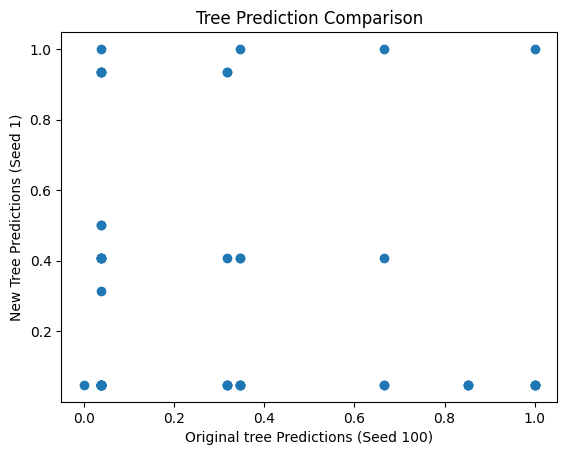

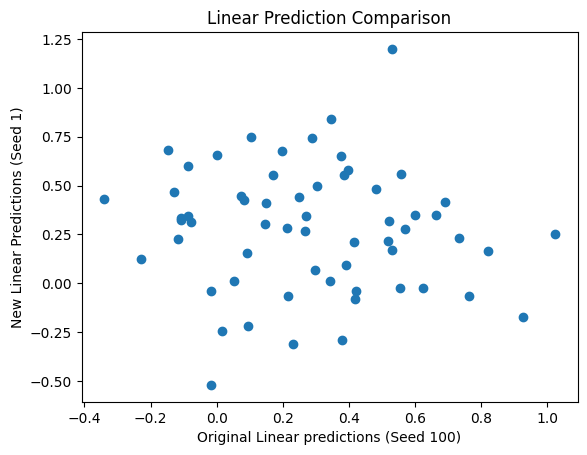

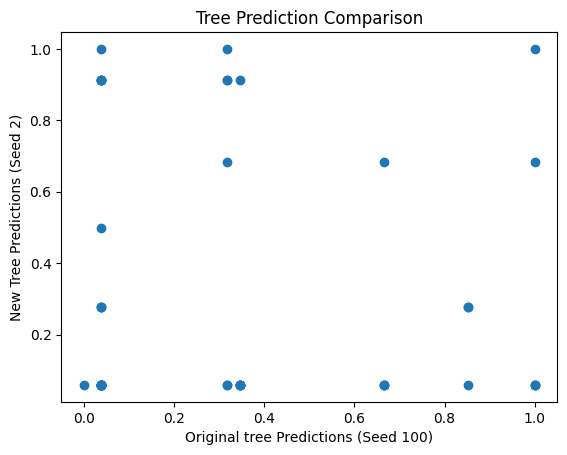

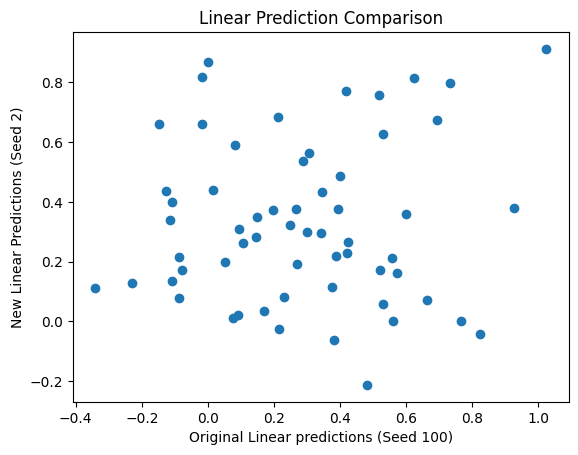

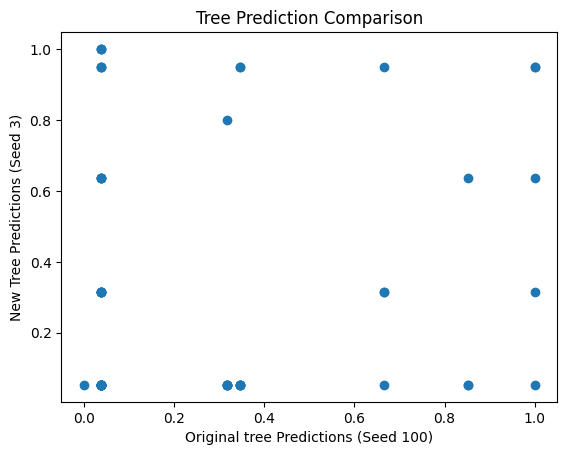

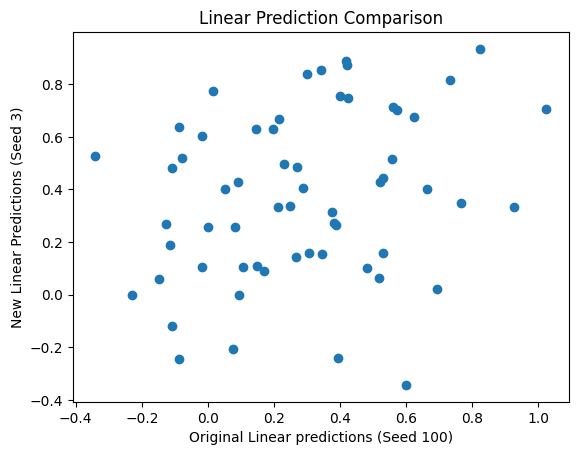

Decision Tree Correlations:
Seed 100 vs Seed 1: -0.0313
Seed 100 vs Seed 2: 0.0715
Seed 100 vs Seed 3: 0.1308

Linear Model Correlations:
Seed 100 vs Seed 1: -0.0822
Seed 100 vs Seed 2: 0.0734
Seed 100 vs Seed 3: 0.2541

Decision Tree Regressions:

Seed 100 vs Seed 1
Intercept: 0.2824
Slope: -0.0329
R²: 0.0010

Seed 100 vs Seed 2
Intercept: 0.2566
Slope: 0.0769
R²: 0.0051

Seed 100 vs Seed 3
Intercept: 0.2916
Slope: 0.1453
R²: 0.0171

Linear Model Regressions:

Seed 100 vs Seed 1
Intercept: 0.3041
Slope: -0.0870
R²: 0.0068

Seed 100 vs Seed 2
Intercept: 0.3110
Slope: 0.0659
R²: 0.0054

Seed 100 vs Seed 3
Intercept: 0.2955
Slope: 0.2671
R²: 0.0646


In [20]:
#question 4

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

#par a
import matplotlib.pyplot as plt

seeds = [1,2,3]

for seed in seeds:

    plt.scatter(tree_preds["Seed 100"], tree_preds[f"Seed {seed}"])
    plt.xlabel("Original tree Predictions (Seed 100)")
    plt.ylabel("New Tree Predictions (Seed " + str(seed) + ")")
    plt.title("Tree Prediction Comparison")
    plt.show()
    plt.scatter(linear_preds["Seed 100"], linear_preds[f"Seed {seed}"])
    plt.xlabel("Original Linear predictions (Seed 100)")
    plt.ylabel("New Linear Predictions (Seed " + str(seed) + ")")
    plt.title("Linear Prediction Comparison")
    plt.show()


#par b
tree_preds = pd.DataFrame(tree_preds)
linear_preds = pd.DataFrame(linear_preds)

print("Decision Tree Correlations:")

for seed in seeds:
    corr = tree_preds["Seed 100"].corr(tree_preds[f"Seed {seed}"])
    print(f"Seed 100 vs Seed {seed}: {corr:.4f}")

print("\nLinear Model Correlations:")

for seed in seeds:
    corr = linear_preds["Seed 100"].corr(linear_preds[f"Seed {seed}"])
    print(f"Seed 100 vs Seed {seed}: {corr:.4f}")


#part c
print("\nDecision Tree Regressions:")

for seed in seeds:
    X_reg = tree_preds[["Seed 100"]]
    y_reg = tree_preds[f"Seed {seed}"]

    reg = LinearRegression().fit(X_reg, y_reg)

    print(f"\nSeed 100 vs Seed {seed}")
    print(f"Intercept: {reg.intercept_:.4f}")
    print(f"Slope: {reg.coef_[0]:.4f}")
    print(f"R²: {reg.score(X_reg, y_reg):.4f}")

print("\nLinear Model Regressions:")

for seed in seeds:
    X_reg = linear_preds[["Seed 100"]]
    y_reg = linear_preds[f"Seed {seed}"]

    reg = LinearRegression().fit(X_reg, y_reg)

    print(f"\nSeed 100 vs Seed {seed}")
    print(f"Intercept: {reg.intercept_:.4f}")
    print(f"Slope: {reg.coef_[0]:.4f}")
    print(f"R²: {reg.score(X_reg, y_reg):.4f}")

Question 5: The linear models have relatively similar coefficients and predictions across different training and test splits. Their correlations stay fairly consistent and are .957, .9698, and .9892 for seeds 1, 2, and 3 respectively. However, the decision trees have larger variation across the three different splits. Their correlations are .8167, .7398, and .8492 for the same seeds. Overall, the linear models are more consistent across training and test splits, whereas the decision trees are less consistent and more sensitive to changes in the training data.

Question 6: The statement is generally true, especially for the linear models. Linear predictionas have correlations 0.96–0.99 across splits, regression slopes close to 1, intercepts close to, and R^2 values of about 0.92–0.98. This shows that changes in coefficients do not necessarily produce large variation in predictions. The trees also produce similar predictions but less consistently. Their correlations are about 0.74–0.85 and comparison R^2 values are about 0.55–0.72. I think the models can change in appearance while keeping similar predictions, though the trees shows lower predictability.

### *Reflection on AI assistance
In your own words without generative AI.

Thanks to assistance from AI, we were able to make a series of improvements to our phase 1 solution. For example, we included an extra step in our cleaning process that removed duplicate rows from our data and tightened the wording in our responces to Q5 and Q6. Any suggestions that required verification were tested in a copy of this notebook before being implemented into the phase 2 solution. 

However, the AI's suggestions were extremely limited in their power. Much of the recommendations either had nothing to do with each problem or asked for the inclusion of details that were not asked for in the questions' wordings. Such a result is interesting, as our prompt specifically asked that the AI not provide recommendations that are irrelevant to what the questions ask.

Our group has no majors concerns about the validity of our solutions or our assistance from AI. However, it may be necessary to provide additional context to our prompt, such as the data or methods we used, to further guide the AI towards giving more helpful suggestions